1- IMPORTS

In [ ]:
import cv2 as cv
import os
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, log_loss, roc_curve, auc
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import matplotlib.pyplot as plt
import time
from xgboost import XGBClassifier
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

2- DATASET PATHS

In [2]:
train_image_path = "D:/UND subjects/Applied Machine Learning DATA532/project/final_dataset10000/train/images"
train_txt_path = "D:/UND subjects/Applied Machine Learning DATA532/project/final_dataset10000/train/labels"

valid_image_path = "D:/UND subjects/Applied Machine Learning DATA532/project/final_dataset10000/valid/images"
valid_txt_path = "D:/UND subjects/Applied Machine Learning DATA532/project/final_dataset10000/valid/labels"

test_image_path = "D:/UND subjects/Applied Machine Learning DATA532/project/final_dataset10000/test/images"
test_txt_path = "D:/UND subjects/Applied Machine Learning DATA532/project/final_dataset10000/test/labels"

3- LOAD TRAIN IMAGES

In [3]:
def train_image(train_image_path):
    traineded_images = []
    filenames = []
    opened_images = []
    failed_images = []  # Track images that failed to open
    for filename in os.listdir(train_image_path):  
        if filename.endswith(".jpg"):            
            file_path = os.path.join(train_image_path, filename)
            train_images = cv.imread(file_path)
            
            if train_images is None:
                print(f"Error loading train image: {filename}")
                failed_images.append(filename)
                continue     
            opened_images.append(filename)
            gray_train_image = cv.cvtColor(train_images, cv.COLOR_BGR2GRAY)
            traineded_images.append(gray_train_image)
            filenames.append(filename)

    return traineded_images, filenames


4- LOAD TRAIN LABELS

In [4]:
def load_train_labels_ORB(train_txt_path, valid_filenames_train_ORB):
    train_labels_ORB = []
    for filename in valid_filenames_train_ORB:  # Only process valid filenames
        label_file_path = os.path.join(train_txt_path, filename.replace(".jpg", ".txt"))
        if os.path.exists(label_file_path):
            with open(label_file_path, 'r') as file:
                label_line = file.read().strip().split()
                class_label = int(label_line[0])
                train_labels_ORB.append(class_label)
        else:
            print(f"Label file missing for {filename}")
                
    return train_labels_ORB

5- LOAD VALIDATION IMAGES

In [5]:
def valid_image(valid_image_path):
    valided_images = []
    filenamesss = []
    opened_images = []
    failed_images = []  # Track images that failed to open
    for filename in os.listdir(valid_image_path):  
        if filename.endswith(".jpg"):            
            file_path = os.path.join(valid_image_path, filename)
            valid_images = cv.imread(file_path)
            
            if valid_images is None:
                print(f"Error loading train image: {filename}")
                failed_images.append(filename)
                continue     
            opened_images.append(filename)
            gray_valid_image = cv.cvtColor(valid_images, cv.COLOR_BGR2GRAY)
            valided_images.append(gray_valid_image)
            filenamesss.append(filename)

    return valided_images, filenamesss

6- LOAD VALIDATION LABELS

In [6]:
def load_valid_labels_ORB(valid_txt_path, valid_filenames_valid_ORB):
    valid_labels_ORB = []
    for filename in valid_filenames_valid_ORB:  # Only process valid filenames
        label_file_path = os.path.join(valid_txt_path, filename.replace(".jpg", ".txt"))
        if os.path.exists(label_file_path):
            with open(label_file_path, 'r') as file:
                label_line = file.read().strip().split()
                class_label = int(label_line[0])
                valid_labels_ORB.append(class_label)
        else:
            print(f"Label file missing for {filename}")
                
    return valid_labels_ORB

7- LOAD TEST IMAGES

In [7]:
def test_image(test_image_path):
    tested_images = []
    filenamess = []
    opened_images = []
    failed_images = []
    for filename in os.listdir(test_image_path):
        if filename.endswith(".jpg"):
            file_path = os.path.join(test_image_path, filename)
            testimages = cv.imread(file_path)

            if testimages is None:
                print(f"Error loading test image {filename}")
                failed_images.append(filename)
                continue
            opened_images.append(filename)
            gray_test_images = cv.cvtColor(testimages, cv.COLOR_BGR2GRAY)
            tested_images.append(gray_test_images)
            filenamess.append(filename)

    return tested_images, filenamess

8- LOAD TEST LABELS

In [8]:
def load_test_labels_ORB(test_txt_path, valid_filenames_test_ORB):
    test_labels_ORB = []
    for filename in valid_filenames_test_ORB:  # Only process valid filenames
        label_file_path = os.path.join(test_txt_path, filename.replace(".jpg", ".txt"))
        if os.path.exists(label_file_path):
            with open(label_file_path, 'r') as file:
                label_line = file.read().strip().split()
                class_label = int(label_line[0])
                test_labels_ORB.append(class_label)

    return test_labels_ORB

9- EXTRACT FEATURES WITH ORB FROM TRAINING

In [ ]:
def ORB_train(gray_train_image, filenames):
    start_time = time.time()
    ORB_train = cv.ORB_create(fastThreshold=3)
    train_features_ORB = []
    train_keypoints_ORB = []
    train_valid_filenames_ORB = []  # To store filenames of images with valid keypoints/descriptors
    total_train_keypoints_ORB = 0

    for gimg, filename in zip(gray_train_image, filenames):
        kp_train, des_train = ORB_train.detectAndCompute(gimg, None)
        if des_train is not None:  # Only process images with descriptors
            flattened_descriptor = np.mean(des_train, axis=0)
            train_features_ORB.append(flattened_descriptor)
            train_keypoints_ORB.append(kp_train)
            train_valid_filenames_ORB.append(filename)  # Add the filename if the image has keypoints/descriptors
            total_train_keypoints_ORB += len(kp_train)  # Add the number of keypoints in this image

    train_features_ORB = np.array(train_features_ORB)

    end_time = time.time()
    ORB_train_time = end_time - start_time
    ORB_execution_train_time_minutes = ORB_train_time/60
    print(f"ORB execution Train time is {ORB_execution_train_time_minutes} minute")
    print(f"total number of ORBtrain keypoints: {total_train_keypoints_ORB} for {len(gray_train_image)} images")
    return train_features_ORB, train_valid_filenames_ORB, ORB_execution_train_time_minutes, total_train_keypoints_ORB

10- EXTRACT FEATURES WITH ORB FROM VALIDATION

In [10]:
def ORB_valid(gray_valid_image, filenamesss):
    start_time = time.time()
    ORB_valid = cv.ORB_create()
    valid_features_ORB = []
    valid_keypoints_ORB = []
    valid_valid_filenames_ORB= []  # To store filenames of images with valid keypoints/descriptors
    total_valid_keypoints_ORB = 0

    for gimg, filename in zip(gray_valid_image, filenamesss):
        kp_valid, des_valid = ORB_valid.detectAndCompute(gimg, None)
        if des_valid is not None:  # Only process images with descriptors
            flattened_descriptor = np.mean(des_valid, axis=0)
            valid_features_ORB.append(flattened_descriptor)
            valid_keypoints_ORB.append(kp_valid)
            valid_valid_filenames_ORB.append(filename)  # Add the filename if the image has keypoints/descriptors
            total_valid_keypoints_ORB+= len(kp_valid)  # Add the number of keypoints in this image

    valid_features_ORB = np.array(valid_features_ORB)

    end_time = time.time()
    ORB_valid_time = end_time - start_time
    ORB_execution_valid_time_minutes = ORB_valid_time/60
    print(f"ORBexecution Valid time is {ORB_execution_valid_time_minutes} minute")
    print(f"total number of ORB Valid keypoints: {total_valid_keypoints_ORB} for {len(gray_valid_image)} images")
    return valid_features_ORB, valid_valid_filenames_ORB, ORB_execution_valid_time_minutes, total_valid_keypoints_ORB


11- EXTRACT FEATURES WITH ORB FROM TESTING IMAGES

In [11]:
def ORB_test(gray_test_image, filenamess):
    start_time = time.time()
    ORB_test = cv.ORB_create()
    test_features_ORB= []
    test_keypoints_ORB = []
    test_valid_filenames_ORB = []  # To store filenames of images with valid keypoints/descriptors
    total_test_keypoints_ORB = 0

    for gimg, filename in zip(gray_test_image, filenamess):
        kp_test, des_test = ORB_test.detectAndCompute(gimg, None)
        if des_test is not None:  # Only process images with descriptors
            flattened_descriptor = np.mean(des_test, axis=0)
            test_features_ORB.append(flattened_descriptor)
            test_keypoints_ORB.append(kp_test)
            test_valid_filenames_ORB.append(filename)  # Add the filename if the image has keypoints/descriptors
            total_test_keypoints_ORB += len(kp_test)  # Add the number of keypoints in this image

    test_features_ORB = np.array(test_features_ORB)

    end_time = time.time()
    ORB_test_time = end_time - start_time
    ORB_execution_test_time_minutes = ORB_test_time/60
    print(f"ORBexecution test time is {ORB_execution_test_time_minutes} minute")
    print(f"total number of ORB test keypoints: {total_test_keypoints_ORB} for {len(gray_test_image)} images")
    return test_features_ORB, test_valid_filenames_ORB, ORB_execution_test_time_minutes, total_test_keypoints_ORB

12- BUILD LOGREG CLASSIFIER AND XGBOOST

In [ ]:
def train_test_logreg_ORB(train_features_ORB, train_labels_ORB, valid_features_ORB, valid_labels_ORB, test_features_ORB, test_labels_ORB):
    '''Step 1: Split data first, then scale'''
    X_train = train_features_ORB
    y_train = train_labels_ORB
    X_valid = valid_features_ORB
    y_valid = valid_labels_ORB
    X_test = test_features_ORB
    y_test = test_labels_ORB
    '''Step 2: Initialize and fit the scaler '''
    scaler_ORB= StandardScaler()
    X_train_scaled_ORB = scaler_ORB.fit_transform(X_train)
    '''Step 3: Transform X_test with the same scaler'''
    X_valid_scaled_ORB = scaler_ORB.transform(X_valid) 
    X_test_scaled_ORB= scaler_ORB.transform(X_test)
    '''Step 4: Grid search for logreg'''
    param_grid_lr = {'logisticregression__C': [0.01, 0.1, 0.5, 1, 10, 50, 100]}
    '''Step 5: Train Logistic Regression'''
    start_train_time = time.time()  # Start time for training
    pipe_lr = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler()),  # Ensure scaling is included in the pipeline
    ('logisticregression', LogisticRegression(max_iter=1000, random_state=42))
])
    kf_regular = KFold(n_splits=5, shuffle=True, random_state=42)
    oof_preds_train = np.zeros((X_train_scaled_ORB.shape[0],)) #added feature
    y_train = np.array(y_train)

    # loop for each fold
    for train_idx, val_idx in kf_regular.split(X_train_scaled_ORB):
        X_tr, X_val = X_train_scaled_ORB[train_idx], X_train_scaled_ORB[val_idx]
        y_tr, y_val = y_train[train_idx], y_train[val_idx]  

        # step 6: Perform GridSearchCV with Logistic Regression and KFold
        logreg_kf = GridSearchCV(pipe_lr, param_grid_lr, cv=5, scoring='accuracy', n_jobs=-1, verbose=1)
        logreg_kf.fit(X_tr, y_tr)
        best_lr_model = logreg_kf.best_estimator_
        oof_preds_train[val_idx] = best_lr_model.predict_proba(X_val)[:, 1]
    '''
    This way, when all 5 folds are done, oof_preds_train contains predictions for every training sample, 
    but made only using models that didn't train on that sample — avoiding data leakage.
    '''
    '''
    ✅ Summary:
    You're using nested cross-validation:
    Outer loop = 5-fold split
    Inner loop = GridSearchCV with 5-fold.
    After each fold, you're saving the predicted probabilities on validation data.
    This is a robust way to evaluate and tune models without overfitting on the training data.
    '''
    end_train_time = time.time()  # End time for training
    logreg_train_time = end_train_time - start_train_time  # Time for training
    logred_train_execution_test_time_minutes = logreg_train_time/60
    best_lr_model.fit(X_train_scaled_ORB, y_train)

    '''Step 6: Make predictions''' 
    logreg_train_pred_ORB = best_lr_model.predict_proba(X_train_scaled_ORB)[:, 1]
    logreg_valid_pred_ORB= best_lr_model.predict_proba(X_valid_scaled_ORB)[:, 1]
    logreg_test_pred_ORB= best_lr_model.predict_proba(X_test_scaled_ORB)[:, 1]
    train_prediction_ORB= best_lr_model.predict(X_train_scaled_ORB)
    valid_prediction_ORB = best_lr_model.predict(X_valid_scaled_ORB)
    test_prediction_ORB= best_lr_model.predict(X_test_scaled_ORB)
    '''Step 7: Combine original features with LogReg outputs'''
    X_train_combined_ORB = np.hstack((X_train_scaled_ORB, oof_preds_train.reshape(-1, 1)))
    X_valid_combined_ORB = np.hstack((X_valid_scaled_ORB, logreg_valid_pred_ORB.reshape(-1, 1)))
    X_test_combined_ORB = np.hstack((X_test_scaled_ORB, logreg_test_pred_ORB.reshape(-1, 1)))
    '''Step 8: Get evaluation metrics'''
    train_score_ORB = best_lr_model.score(X_train_scaled_ORB, y_train)
    valid_score_ORB = best_lr_model.score(X_valid_scaled_ORB, y_valid)
    test_score_ORB= best_lr_model.score(X_test_scaled_ORB, y_test)
    class_report_ORB = classification_report(y_test, test_prediction_ORB, target_names=["Car", "Ship"]) 
    cm_ORB= confusion_matrix(y_test, test_prediction_ORB)
    train_size_ORB= X_train_scaled_ORB.shape
    valid_size_ORB = X_valid_scaled_ORB.shape
    test_size_ORB = X_test_scaled_ORB.shape
    cross_entropy_loss_logreg = log_loss(y_test, logreg_test_pred_ORB)
    class_names = ['Car', 'Ship']
    prediction_labels = [class_names[pred] for pred in test_prediction_ORB]
    '''Step 11: Initializing the XGBoost model'''
    start_test_time = time.time()
    param_grid_xgb_ORB = {
        'xgbclassifier__n_estimators': [10, 100, 200], #The number of trees (or boosting rounds) in the model.
        'xgbclassifier__max_depth': [3, 5], #Maximum depth of each tree (branches).
        'xgbclassifier__learning_rate': [0.01, 0.1, 0.2], #Controls how much each tree contributes to the final prediction.
        'xgbclassifier__subsample': [0.8, 1.0], #Fraction of the training data randomly sampled for growing each tree.1.0 means use all the data. 0.8 means use only 80% for each tree — helps prevent overfitting.
        'xgbclassifier__colsample_bytree': [0.8, 1.0] #Fraction of features (columns) randomly sampled for each tree.Like subsample, this helps reduce overfitting and improve generalization.
    }       
    pipe_xgb_ORB = Pipeline([
        ('imputer', SimpleImputer(strategy='mean')),
        ('scaler', StandardScaler()),
        ('xgbclassifier', XGBClassifier())
    ])  
    kf_regular = KFold(n_splits=5, shuffle=True, random_state=42)
    grid_xgb_kf_regular_ORB = GridSearchCV(pipe_xgb_ORB, param_grid_xgb_ORB, cv=kf_regular, scoring='accuracy', n_jobs=-1, verbose=1)
    grid_xgb_kf_regular_ORB.fit(X_train_combined_ORB, y_train)
    xgb_model_ORB = XGBClassifier(    
    n_estimators=grid_xgb_kf_regular_ORB.best_params_['xgbclassifier__n_estimators'],
    max_depth=grid_xgb_kf_regular_ORB.best_params_['xgbclassifier__max_depth'],
    learning_rate=grid_xgb_kf_regular_ORB.best_params_['xgbclassifier__learning_rate'],
    subsample=grid_xgb_kf_regular_ORB.best_params_['xgbclassifier__subsample'],
    colsample_bytree=grid_xgb_kf_regular_ORB.best_params_['xgbclassifier__colsample_bytree'],
    # use_label_encoder=False,
    eval_metric='logloss',
    random_state=42,
    )
    #Train on full combined training set
    xgb_model_ORB.fit(
        X_train_combined_ORB, y_train,
        eval_set=[(X_valid_combined_ORB, y_valid)],  # Use validation set
        verbose=False
        )
    xgb_predictions_ORB = xgb_model_ORB.predict(X_test_combined_ORB)
    xgb_probabilities_ORB = xgb_model_ORB.predict_proba(X_test_combined_ORB)[:, 1]
    end_test_time = time.time()  # End time for testing
    test_time = end_test_time - start_test_time  # Time for testing
    XGBoost_execution_test_time_minutes = test_time/60
    '''Step 12: Get evaluation metrics'''
    class_report_XGBoost_ORB = classification_report(y_test, xgb_predictions_ORB, target_names=["Car", "Ship"]) 
    cm_XGBoost_ORB = confusion_matrix(y_test, xgb_predictions_ORB)
    cross_entropy_loss_XGBoost = log_loss(y_test, xgb_probabilities_ORB)
    train_score_XGBoost_ORB = xgb_model_ORB.score(X_train_combined_ORB, y_train)
    valid_score_XGBoost_ORB = xgb_model_ORB.score(X_valid_combined_ORB, y_valid)
    test_score_XGBoost_ORB = xgb_model_ORB.score(X_test_combined_ORB, y_test)
    train_size_XGBoost_ORB = X_train_combined_ORB.shape
    valid_size_XGBoost_ORB = X_valid_combined_ORB.shape
    test_size_XGBoost_ORB = X_test_combined_ORB.shape
   
    return y_test, logreg_test_pred_ORB, train_size_ORB, xgb_probabilities_ORB, valid_size_ORB, test_size_ORB, class_report_ORB, train_prediction_ORB, valid_prediction_ORB, test_prediction_ORB, logreg_kf, grid_xgb_kf_regular_ORB, train_size_XGBoost_ORB,valid_size_XGBoost_ORB, train_score_ORB, valid_score_ORB, test_score_ORB, cm_ORB, train_score_XGBoost_ORB, valid_score_XGBoost_ORB, test_score_XGBoost_ORB, cm_XGBoost_ORB, \
        cross_entropy_loss_logreg, cross_entropy_loss_XGBoost, logred_train_execution_test_time_minutes, XGBoost_execution_test_time_minutes, test_size_XGBoost_ORB, valid_score_XGBoost_ORB, class_report_XGBoost_ORB


13- PRINTS

In [13]:
def prints(total_train_keypoints_ORB, total_valid_keypoints_ORB, total_test_keypoints_ORB, ORB_execution_valid_time_minutes, ORB_execution_test_time_minutes, ORB_execution_train_time_minutes, train_size_ORB, valid_size_ORB, test_size_ORB, class_report_ORB, train_prediction_ORB, valid_prediction_ORB, test_prediction_ORB, train_score_ORB, valid_score_ORB, test_score_ORB, cm_ORB, cross_entropy_loss_logreg, logred_train_execution_test_time_minutes, logreg_kf, grid_xgb_kf_regular_ORB, train_size_XGBoost_ORB, valid_size_XGBoost_ORB,test_size_XGBoost_ORB, train_score_XGBoost_ORB, valid_score_XGBoost_ORB, test_score_XGBoost_ORB, class_report_XGBoost_ORB, cm_XGBoost_ORB, cross_entropy_loss_XGBoost, XGBoost_execution_test_time_minutes):
    print("Best parameters for ORB Logistic Regression:", logreg_kf.best_params_)
    print("Best score for ORBLogistic Regression:", logreg_kf.best_score_)
    print(f"Train size ORB {train_size_ORB}\n")
    print(f"Valid size ORB {valid_size_ORB}\n")
    print(f"Test size ORB {test_size_ORB}\n")
    print(f"Class report ORB\n{class_report_ORB}\n")
    print(f"Train Predictions ORB {train_prediction_ORB}")
    print(f"Valid Predictions ORB {valid_prediction_ORB}\n")
    print(f"Test Predictions ORB {test_prediction_ORB}\n")
    print(f"Train Score ORB {train_score_ORB* 100:.2f}%\n")
    print(f"Valid Score ORB {valid_score_ORB * 100:.2f}%\n")
    print(f"Test Score ORB {test_score_ORB* 100:.2f}%\n")
    print(f"Confusion matrix for ORB:\n {cm_ORB}\n")
    print(f"Cross Entropy Loss for Logistic Regression for ORB: {cross_entropy_loss_logreg}\n")
    print(f"logreg execution test time: {logred_train_execution_test_time_minutes} minute")

    print("Best parameters with Regular KFold for XGBoost:", grid_xgb_kf_regular_ORB.best_params_)
    print("Best score with Regular KFold for XGBoost:", grid_xgb_kf_regular_ORB.best_score_)
    print(f"Train XGBoost size ORB: {train_size_XGBoost_ORB}\n")
    print(f"Valid XGBoost size ORB: {valid_size_XGBoost_ORB}\n")
    print(f"Test XGBoost size ORB: {test_size_XGBoost_ORB}\n")
    print(f"XGBoost Train Accuracy combined with ORB: {train_score_XGBoost_ORB * 100:.2f}%\n")
    print(f"XGBoost Valid Accuracy combined with ORB: {valid_score_XGBoost_ORB * 100:.2f}%\n")
    print(f"XGBoost Test Accuracy combined with ORB: {test_score_XGBoost_ORB * 100:.2f}%\n")
    print(f"class report XGBoost combined with ORB:\n{class_report_XGBoost_ORB}\n")
    print(f"Confusion matrix for XGBoost combined with ORB:\n {cm_XGBoost_ORB}\n")
    print(f"Cross Entropy Loss for XGBoost combined with ORB is: {cross_entropy_loss_XGBoost}")
    print(f"XGBoost execution test time is {XGBoost_execution_test_time_minutes} minute")

    '''9- PRINT TOTAL NUMBER OF FEATURES AND TIME TAKEN'''
    total_ORB_features = total_train_keypoints_ORB + total_valid_keypoints_ORB + total_test_keypoints_ORB
    print(f"Total ORB eatures: {total_ORB_features}")
    total_ORB_time = ORB_execution_train_time_minutes + ORB_execution_valid_time_minutes + ORB_execution_test_time_minutes + logred_train_execution_test_time_minutes + XGBoost_execution_test_time_minutes
    print(f"Total ORB time: {total_ORB_time} minute")

14- PLOTS

In [ ]:
def plots(y_test, logreg_test_pred_ORB, xgb_probabilities_ORB, ORB_execution_valid_time_minutes, ORB_execution_test_time_minutes, ORB_execution_train_time_minutes, train_score_ORB, test_score_ORB, cm_ORB, cross_entropy_loss_logreg, logred_train_execution_test_time_minutes, train_score_XGBoost_ORB, test_score_XGBoost_ORB, cm_XGBoost_ORB, cross_entropy_loss_XGBoost, XGBoost_execution_test_time_minutes):
    '''Plot 1: Plot confusion matrix for logreg'''
    plt.figure(figsize=(6,6))
    sns.heatmap(cm_ORB, annot=True, fmt='d', cmap='Blues', xticklabels=["Car", "Ship"], yticklabels=["Car", "Ship"])
    plt.title("Confusion Matrix for ORB")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

    '''Plot 2: Plot confusion matrix for XGBoost'''
    plt.figure(figsize=(6,6))
    sns.heatmap(cm_XGBoost_ORB, annot=True, fmt='d', cmap='Blues', xticklabels=["Car", "Ship"], yticklabels=["Car", "Ship"])
    plt.title("Confusion Matrix for XGBoost combined with ORB")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

    '''Plot 3: confusion matrix for Logreg VS XGBoost'''
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    sns.heatmap(cm_ORB, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax[0])  
    ax[0].set_title('ORB Logistic Regression Confusion Matrix')  
    sns.heatmap(cm_XGBoost_ORB, annot=True, fmt='d', cmap='Reds', cbar=False, ax=ax[1])
    ax[1].set_title('ORB XGBoost Confusion Matrix')
    plt.tight_layout()
    plt.show()

    '''Plot 4: Plot ROC Curve for ORB logreg'''
    fpr, tpr, thresholds = roc_curve(y_test, logreg_test_pred_ORB)
    roc_auc = auc(fpr, tpr)
    plt.figure()
    plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC) Curve for logreg ORB')
    plt.legend(loc="lower right")
    plt.show()

    '''Plot 5: Plot ROC Curve for XGBoost'''
    fpr, tpr, thresholds = roc_curve(y_test, xgb_probabilities_ORB)    
    roc_auc = auc(fpr, tpr)
    plt.figure()
    plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC) Curve for XGBoost ORB')
    plt.legend(loc="lower right")
    plt.show()
    
    '''Plot 6 EXECUTION TIME ORB'''
    plt.bar(['Train', 'valid', 'Test', 'Logistic Regression', 'XGBoost'], [ORB_execution_train_time_minutes, ORB_execution_valid_time_minutes, ORB_execution_test_time_minutes, logred_train_execution_test_time_minutes, XGBoost_execution_test_time_minutes], color=['blue', 'red', 'green', 'orange', 'black'])
    plt.ylabel('Execution Time (minutes)')
    plt.title('Execution Time for ORB, Logreg, XGBoost')
    plt.show()

    '''Plot 7 CROSS ENTROPY LOSS'''
    plt.bar(['ORB Logistic Regression', 'XGBoost'], [cross_entropy_loss_logreg, cross_entropy_loss_XGBoost], color=['blue', 'red'])
    plt.ylabel('cross entropy loss')
    plt.title('cross entropy loss ORB Logistic Regression vs XGBoost')
    plt.show()

    '''Plot 8 Training vs Testing Accuracy'''
    labels = ['Logistic Regression', 'XGBoost']
    train_accuracies = [train_score_ORB, train_score_XGBoost_ORB]
    test_accuracies = [test_score_ORB, test_score_XGBoost_ORB]
    x = range(len(labels))
    width = 0.3
    fig, ax4 = plt.subplots(figsize=(8, 6))
    ax4.bar(x, train_accuracies, width=width, label='ORB Training Accuracy', color='blue')
    ax4.bar([p + width for p in x], test_accuracies, width=width, label='ORB Testing Accuracy', color='red')
    ax4.set_xticks([p + width / 3 for p in x])
    ax4.set_xticklabels(labels)
    ax4.set_ylabel('Accuracy')
    ax4.set_title('ORB Training vs ORB Testing Accuracy')
    ax4.legend()

15- MAIN FUNCTION

ORB execution Train time is 1.8390533248583476 minute
total number of ORBtrain keypoints: 4783175 for 10000 images
ORBexecution Valid time is 0.4096888740857442 minute
total number of ORB Valid keypoints: 1104908 for 2307 images
ORBexecution test time is 0.35130170981089276 minute
total number of ORB test keypoints: 948980 for 1999 images
Fitting 5 folds for each of 7 candidates, totalling 35 fits
Fitting 5 folds for each of 7 candidates, totalling 35 fits
Fitting 5 folds for each of 7 candidates, totalling 35 fits
Fitting 5 folds for each of 7 candidates, totalling 35 fits
Fitting 5 folds for each of 7 candidates, totalling 35 fits
Fitting 5 folds for each of 72 candidates, totalling 360 fits
Best parameters for ORB Logistic Regression: {'logisticregression__C': 10}
Best score for ORBLogistic Regression: 0.7997495303694429
Train size ORB (9981, 32)

Valid size ORB (2304, 32)

Test size ORB (1998, 32)

Class report ORB
              precision    recall  f1-score   support

         Car

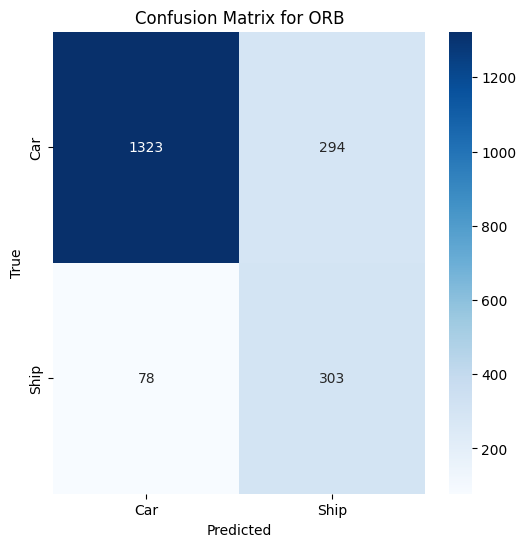

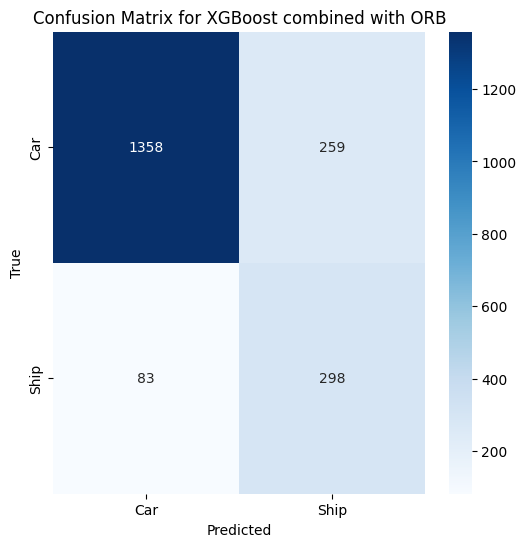

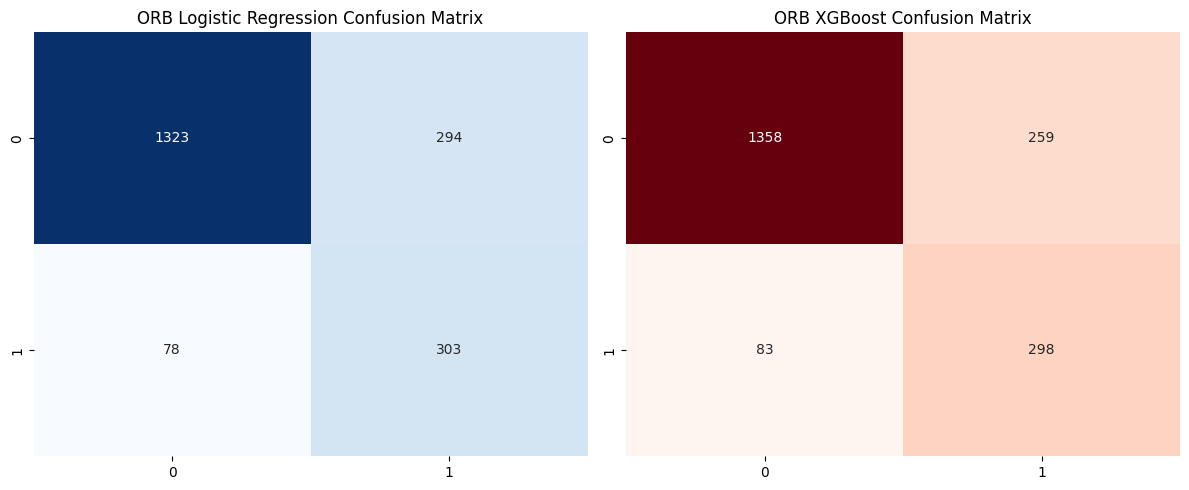

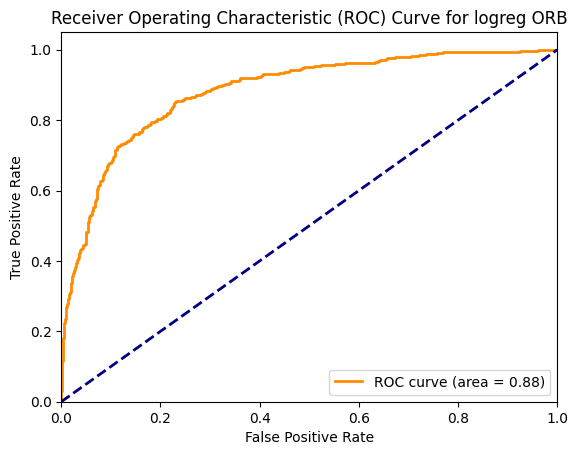

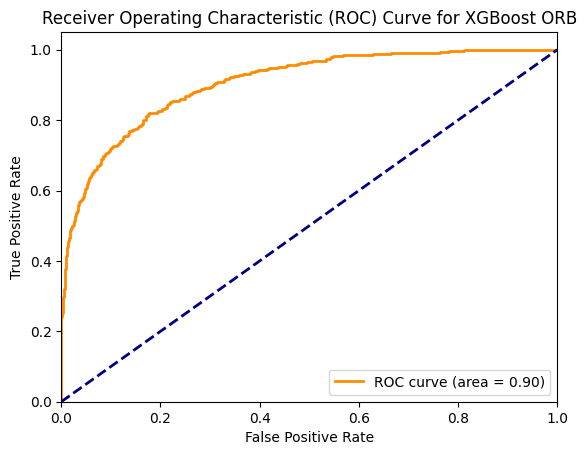

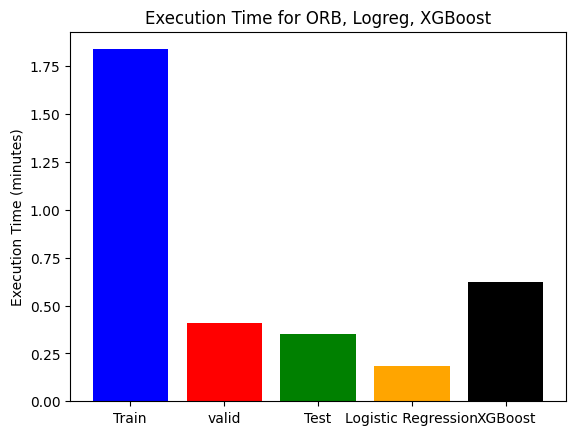

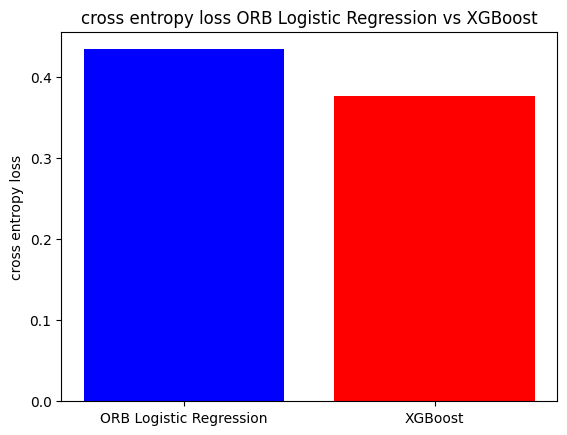

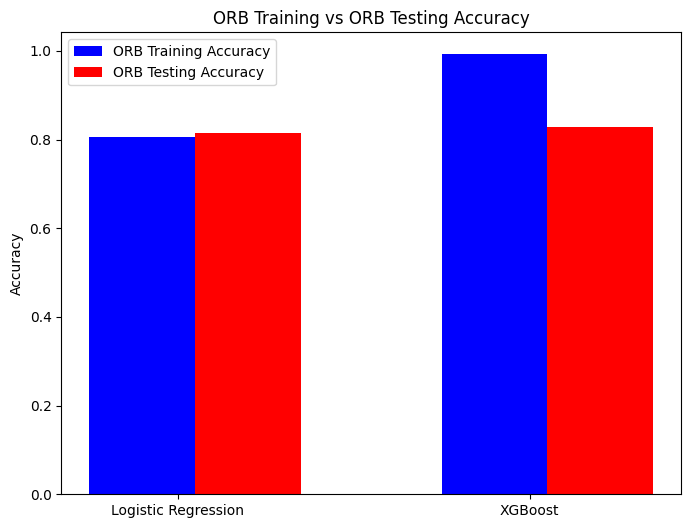

In [15]:
def main():

    # Load training and test data
    traineded_images, filenames = train_image(train_image_path)
    valided_images, filenamesss = valid_image(valid_image_path)
    tested_images, filenamess = test_image(test_image_path)

    # Get valid filenames after ORB processing
    train_features_ORB, train_valid_filenames_ORB, ORB_execution_train_time_minutes, total_train_keypoints_ORB \
    = ORB_train(traineded_images, filenames)
    valid_features_ORB, valid_valid_filenames_ORB, ORB_execution_valid_time_minutes, total_valid_keypoints_ORB \
    = ORB_valid(valided_images, filenamesss)
    test_features_ORB, test_valid_filenames_ORB, ORB_execution_test_time_minutes, total_test_keypoints_ORB\
    = ORB_test(tested_images, filenamess)

    # Load ORB labels only for valid images (those with keypoints/descriptors)
    train_labels_ORB = load_train_labels_ORB(train_txt_path, train_valid_filenames_ORB)
    valid_labels_ORB = load_valid_labels_ORB(valid_txt_path, valid_valid_filenames_ORB)
    test_labels_ORB = load_test_labels_ORB(test_txt_path, test_valid_filenames_ORB)

    # Proceed with Logistic Regression and XGBoost training ORB
    y_test, logreg_test_pred_ORB, train_size_ORB, xgb_probabilities_ORB, valid_size_ORB, \
    test_size_ORB, class_report_ORB, train_prediction_ORB, valid_prediction_ORB, test_prediction_ORB, \
    logreg_kf, grid_xgb_kf_regular_ORB, train_size_XGBoost_ORB,valid_size_XGBoost_ORB, train_score_ORB, \
    valid_score_ORB, test_score_ORB, cm_ORB, train_score_XGBoost_ORB, valid_score_XGBoost_ORB, \
    test_score_XGBoost_ORB, cm_XGBoost_ORB, cross_entropy_loss_logreg, cross_entropy_loss_XGBoost, \
    logred_train_execution_test_time_minutes, XGBoost_execution_test_time_minutes, test_size_XGBoost_ORB, \
    valid_score_XGBoost_ORB, class_report_XGBoost_ORB = train_test_logreg_ORB(train_features_ORB, \
    train_labels_ORB, valid_features_ORB, valid_labels_ORB, test_features_ORB, test_labels_ORB)
    
    # Prints function
    prints(total_train_keypoints_ORB, total_valid_keypoints_ORB, total_test_keypoints_ORB, \
    ORB_execution_valid_time_minutes, ORB_execution_test_time_minutes, ORB_execution_train_time_minutes, \
    train_size_ORB, valid_size_ORB, test_size_ORB, class_report_ORB, train_prediction_ORB, valid_prediction_ORB, \
    test_prediction_ORB, train_score_ORB, valid_score_ORB, test_score_ORB, cm_ORB, cross_entropy_loss_logreg, \
    logred_train_execution_test_time_minutes, logreg_kf, grid_xgb_kf_regular_ORB, train_size_XGBoost_ORB, \
    valid_size_XGBoost_ORB,test_size_XGBoost_ORB, train_score_XGBoost_ORB, valid_score_XGBoost_ORB, \
    test_score_XGBoost_ORB, class_report_XGBoost_ORB, cm_XGBoost_ORB, cross_entropy_loss_XGBoost, \
    XGBoost_execution_test_time_minutes)

    # Plots function
    plots(y_test, logreg_test_pred_ORB, xgb_probabilities_ORB, ORB_execution_valid_time_minutes, \
    ORB_execution_test_time_minutes, ORB_execution_train_time_minutes, train_score_ORB, test_score_ORB, cm_ORB, \
    cross_entropy_loss_logreg, logred_train_execution_test_time_minutes, train_score_XGBoost_ORB, \
    test_score_XGBoost_ORB, cm_XGBoost_ORB, cross_entropy_loss_XGBoost, XGBoost_execution_test_time_minutes)

if __name__ == "__main__":
    main()